# INLA-style hyperparameter integration versus HMC (CIP-0015)

`INLAHyperparameters` approximates the hyperparameter posterior $p(\theta \mid y)$ with a small weighted design and mixes the Laplace predictions made at each design point. HMC over the hyperparameters targets the *same* density: $\log p(y \mid \theta)$ from the Laplace marginal likelihood, plus the log prior and transform Jacobian, in GPy's unconstrained space. The comparison therefore isolates the quality of the design approximation. It does not test the Laplace approximation itself.

We use 25 Bernoulli observations, an RBF kernel and log-Gaussian priors on both hyperparameters. HMC uses the Hessian at the mode as its mass matrix.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import GPy
from GPy.inference.hyperparameters import INLAHyperparameters

rng = np.random.default_rng(1)
n = 25
X = np.sort(rng.uniform(-3, 3, (n, 1)), axis=0)
Y = (rng.uniform(size=(n, 1)) < 1 / (1 + np.exp(-3 * np.sin(1.5 * X)))).astype(float)

kern = GPy.kern.RBF(1)
kern.lengthscale.set_prior(GPy.priors.LogGaussian(0.0, 1.0), warning=False)
kern.variance.set_prior(GPy.priors.LogGaussian(1.0, 1.0), warning=False)
m = GPy.core.GP(X, Y, kernel=kern, likelihood=GPy.likelihoods.Bernoulli(),
                inference_method=GPy.inference.latent_function_inference.Laplace())
Xs = np.linspace(-3.5, 3.5, 100)[:, None]

## INLA-style fit

In [2]:
t0 = time.time()
inla = INLAHyperparameters(m).fit()
t_inla = time.time() - t0
print(f"design={inla.design_used}, points={len(inla.weights)}, time={t_inla:.1f}s")
print("MAP:", dict(zip(m.parameter_names_flat(), np.round(m.unfixed_param_array, 3))))
mu_map, var_map = m.predict_noiseless(Xs)
p_map = m.predict(Xs)[0]
mu_i, var_i = inla.predict_noiseless(Xs)
p_i = inla.predict(Xs)[0]

design=grid, points=155, time=2.9s
MAP: {np.str_('gp.rbf.variance'): np.float64(1.435), np.str_('gp.rbf.lengthscale'): np.float64(0.602)}


## HMC over the hyperparameters

The sampler is started from the mode with the Hessian as mass matrix. We discard the first 100 draws.

In [3]:
np.random.seed(0)
u_star = inla.u_star.copy()
hmc = GPy.inference.mcmc.HMC(m, M=inla.hessian, stepsize=0.4)
t0 = time.time()
S = hmc.sample(num_samples=1000, hmc_iters=8)[100:]
t_hmc = time.time() - t0
accept = np.mean(np.any(np.diff(S, axis=0) != 0, axis=1))
print(f"HMC: {len(S)} draws kept, acceptance={accept:.2f}, time={t_hmc:.0f}s")
m.optimizer_array = u_star

HMC: 900 draws kept, acceptance=0.99, time=55s


## Hyperparameter marginals

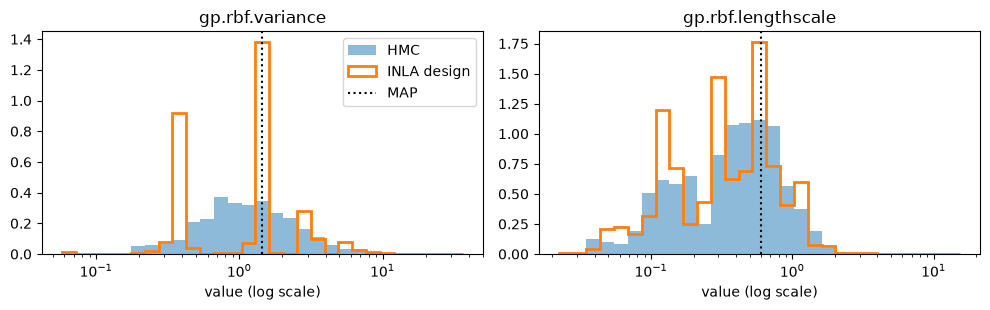

gp.rbf.variance              HMC 2.748 +- 2.360   INLA 2.853 +- 2.703
gp.rbf.lengthscale           HMC 0.797 +- 0.825   INLA 0.758 +- 0.705


In [4]:
names = list(inla.hyperparameter_summary())
vals = []
for u in inla.U:
    m.optimizer_array = u
    vals.append(np.array(m.unfixed_param_array, dtype=float))
m.optimizer_array = u_star
vals = np.array(vals)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for j, ax in enumerate(axes):
    bins = np.geomspace(min(S[:, j].min(), vals[:, j].min()), max(S[:, j].max(), vals[:, j].max()), 30)
    ax.hist(S[:, j], bins=bins, density=True, alpha=0.5, label="HMC")
    ax.hist(vals[:, j], bins=bins, weights=inla.weights, density=True, histtype="step", lw=2, label="INLA design")
    ax.axvline(m.unfixed_param_array[j], color="k", ls=":", label="MAP")
    ax.set_xscale("log"); ax.set_title(names[j]); ax.set_xlabel("value (log scale)")
axes[0].legend()
plt.tight_layout(); plt.show()

summary = inla.hyperparameter_summary()
for j, name in enumerate(names):
    print(f"{name:28s} HMC {S[:, j].mean():.3f} +- {S[:, j].std():.3f}   INLA {summary[name][0]:.3f} +- {summary[name][1]:.3f}")

## Predictions

For HMC we average the Laplace predictions over 250 thinned draws, using the law of total variance as for the INLA design.

In [5]:
idx = np.linspace(0, len(S) - 1, 250).astype(int)
mus, vs, ps = [], [], []
for k in idx:
    m.kern.variance = S[k, names.index('gp.rbf.variance')]
    m.kern.lengthscale = S[k, names.index('gp.rbf.lengthscale')]
    a, b = m.predict_noiseless(Xs)
    mus.append(a); vs.append(b); ps.append(m.predict(Xs)[0])
m.optimizer_array = u_star
mus, vs, ps = map(np.array, (mus, vs, ps))
mu_h = mus.mean(0)
var_h = (vs + mus**2).mean(0) - mu_h**2
p_h = ps.mean(0)

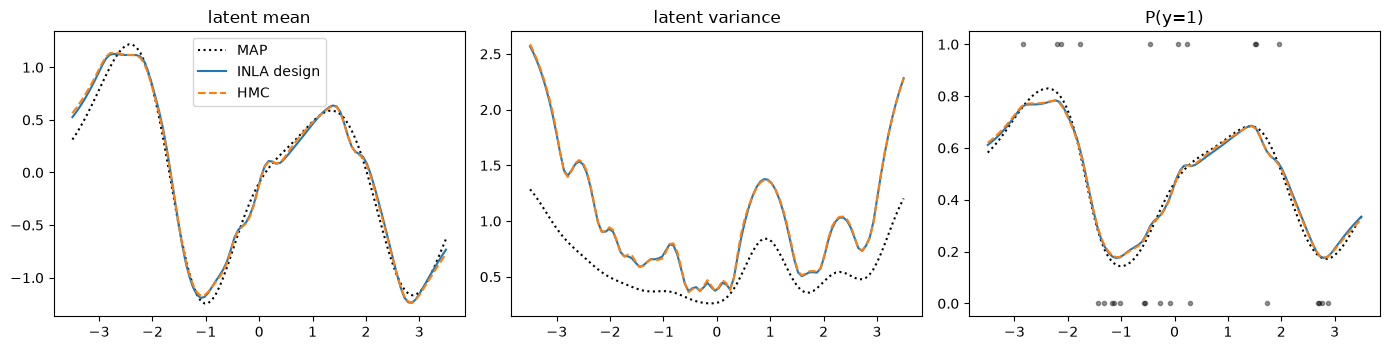

max |INLA - HMC|: latent mean 0.040, latent variance 0.041, P(y=1) 0.010
max |MAP  - HMC|: latent mean 0.251, latent variance 1.301, P(y=1) 0.053
cost: INLA design 2.9s (155 Laplace fits) versus HMC 55s


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (a, b, c, title) in zip(axes[:2], [(mu_map, mu_i, mu_h, "latent mean"), (var_map, var_i, var_h, "latent variance")]):
    ax.plot(Xs, a, "k:", label="MAP"); ax.plot(Xs, b, label="INLA design"); ax.plot(Xs, c, "--", label="HMC"); ax.set_title(title)
axes[2].plot(Xs, p_map, "k:"); axes[2].plot(Xs, p_i); axes[2].plot(Xs, p_h, "--"); axes[2].plot(X, Y, "k.", alpha=0.4); axes[2].set_title("P(y=1)")
axes[0].legend(); plt.tight_layout(); plt.show()

def worst(a, b):
    return float(np.abs(a - b).max())
print(f"max |INLA - HMC|: latent mean {worst(mu_i, mu_h):.3f}, latent variance {worst(var_i, var_h):.3f}, P(y=1) {worst(p_i, p_h):.3f}")
print(f"max |MAP  - HMC|: latent mean {worst(mu_map, mu_h):.3f}, latent variance {worst(var_map, var_h):.3f}, P(y=1) {worst(p_map, p_h):.3f}")
print(f"cost: INLA design {t_inla:.1f}s ({len(inla.weights)} Laplace fits) versus HMC {t_hmc:.0f}s")

## Reading the result

The point of the comparison is the last two lines: the INLA-style design should sit close to HMC and closer than the MAP plug-in, at a small fraction of the cost.

### Higher dimensions (d >= 4)

`check_high_dim.py` repeats the accuracy check for 4 and 5 hyperparameters (ARD RBF, Gaussian likelihood with fixed noise), using importance sampling as the reference and, for d = 4, HMC as a cross-check. The findings are recorded in CIP-0015. In short, a tight grid cutoff understates the spread of weakly identified lengthscales, whose posterior has a heavy tail on the constrained scale, and the central composite design is too coarse to recover hyperparameter marginals at these dimensions.